# 실습 — 위험중립 가치평가의 베이지안 확장

덱 `Bayesian_RiskNeutral_JJ.pptx`의 손계산을 코드로 확인하고 규모를 키운다. numpy·scipy·matplotlib만 쓴다 (Colab 바로 실행).

| Lab | 주제 | 덱 파트 |
|---|---|---|
| B1 | 기대수익률 μ의 베이지안 학습과 샤프 비율 λ의 불확실성 | 01·04 |
| B2 | 라돈-니코딤 재가중: P에서 뽑아 Q 가격 계산 | 02 |
| B3 | 사후분포의 마팅게일 성질 (베타-이항) | 03 |
| B4 | 변동성 σ의 사후분포와 옵션 가격 분포 | 04 |
| B5 | 베이지안 LSM: 행사 확률과 수축(릿지) 회귀 | 05 |
| B6 | 신약 개발 실물옵션: 임상 결과로 갱신한 투자 결정 | 05 |

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy.stats import norm, invgamma, beta as betad, t as tdist
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3,'axes.spines.top':False,'axes.spines.right':False})
SAVE=False
import os; os.makedirs('figs',exist_ok=True)
def savefig(n):
    if SAVE: plt.savefig(f'figs/{n}.png',dpi=170,bbox_inches='tight')
BLUE,NAVY,GRAY,RED,GREEN='#2563EB','#1E4E8C','#94A3B8','#C0392B','#2E7D4F'
def bs(S,K,r,s,T,call=True):
    d1=(np.log(S/K)+(r+s*s/2)*T)/(s*np.sqrt(T)); d2=d1-s*np.sqrt(T)
    return S*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2) if call else K*np.exp(-r*T)*norm.cdf(-d2)-S*norm.cdf(-d1)

## B1. 기대수익률 μ는 천천히 배운다
사전분포 $\mu\sim N(8\%,\,5\%^2)$, 실제 $\mu=12\%$, $\sigma=20\%$. 매년 수익률 1개씩 관측하며 정규-정규 켤레 갱신을 한다. 덱 손계산 1-2(4년 관측, 표본평균 15% → 사후 9.4%)도 재현한다.

사후평균 0.094  사후표준편차 0.044721359549995794  사전 가중치 0.7999999999999999


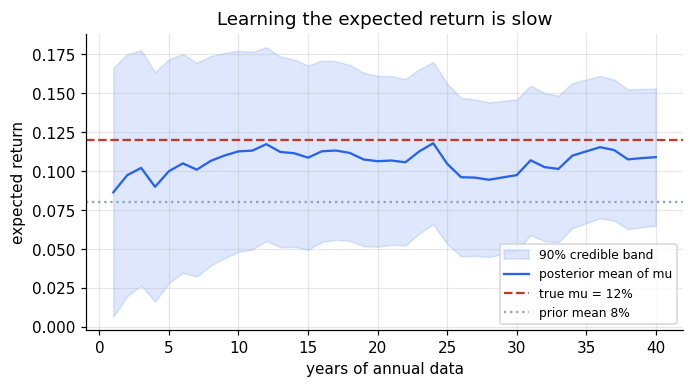

40년 뒤 샤프비율 λ 사후평균 0.295, 사후표준편차 0.134


In [2]:
# 손계산 1-2 재현
p0,pd=1/.05**2,1/(.20/np.sqrt(4))**2
print('사후평균',(p0*.08+pd*.15)/(p0+pd),' 사후표준편차',np.sqrt(1/(p0+pd)),' 사전 가중치',p0/(p0+pd))
rng=np.random.default_rng(1); years=np.arange(1,41); x=rng.normal(.12,.20,40)
m,v=.08,.05**2; M,SD=[],[]
for xi in x:
    prec=1/v+1/.20**2; m=(m/v+xi/.20**2)/prec; v=1/prec; M.append(m); SD.append(np.sqrt(v))
M,SD=np.array(M),np.array(SD)
plt.figure(figsize=(7,3.5))
plt.fill_between(years,M-1.645*SD,M+1.645*SD,color=BLUE,alpha=.15,label='90% credible band')
plt.plot(years,M,color=BLUE,label='posterior mean of mu'); plt.axhline(.12,color=RED,ls='--',label='true mu = 12%')
plt.axhline(.08,color=GRAY,ls=':',label='prior mean 8%'); plt.xlabel('years of annual data'); plt.ylabel('expected return')
plt.title('Learning the expected return is slow'); plt.legend(fontsize=8); savefig('fb1_mu_learning'); plt.show()
lam=(M-.05)/.20; print('40년 뒤 샤프비율 λ 사후평균 %.3f, 사후표준편차 %.3f'%(lam[-1],SD[-1]/.20))

## B2. 라돈-니코딤 재가중 — P에서 뽑고 Q로 가격을 낸다
현실 세계 P(μ=12%)에서 경로를 뽑은 뒤 가중치 $Z_T=\exp(-\lambda W_T-\lambda^2T/2)$, $\lambda=(\mu-r)/\sigma$를 곱해 평균 내면 위험중립 가격이 나온다. 베이즈의 '사전 × 우도'와 같은 재가중이다.

E_P[Z] = 0.9998  (1이어야 한다)
틀린 방법  e^(-rT)E_P[payoff]   = 5.9288
재가중     e^(-rT)E_P[Z·payoff] = 4.8225
BSM                              = 4.8174


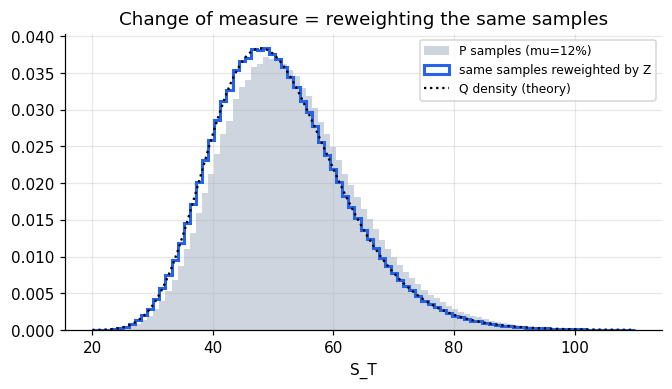

In [3]:
rng=np.random.default_rng(2); S0,K,r,mu,s,T,M=50,50,.05,.12,.30,.5,1_000_000
W=np.sqrt(T)*rng.standard_normal(M); ST=S0*np.exp((mu-s*s/2)*T+s*W)
lam=(mu-r)/s; Z=np.exp(-lam*W-lam**2*T/2); pay=np.maximum(ST-K,0)
print(f'E_P[Z] = {Z.mean():.4f}  (1이어야 한다)')
print(f'틀린 방법  e^(-rT)E_P[payoff]   = {np.exp(-r*T)*pay.mean():.4f}')
print(f'재가중     e^(-rT)E_P[Z·payoff] = {np.exp(-r*T)*(Z*pay).mean():.4f}')
print(f'BSM                              = {bs(S0,K,r,s,T):.4f}')
bins=np.linspace(20,110,90)
plt.figure(figsize=(7,3.5))
plt.hist(ST,bins=bins,density=True,alpha=.45,color=GRAY,label='P samples (mu=12%)')
plt.hist(ST,bins=bins,weights=Z,density=True,histtype='step',lw=2,color=BLUE,label='same samples reweighted by Z')
x=np.linspace(20,110,400); from scipy.stats import lognorm
plt.plot(x,lognorm.pdf(x,s*np.sqrt(T),scale=S0*np.exp((r-s*s/2)*T)),'k:',label='Q density (theory)')
plt.xlabel('S_T'); plt.title('Change of measure = reweighting the same samples'); plt.legend(fontsize=8); savefig('fb2_reweight'); plt.show()

## B3. 사후평균은 마팅게일이다 (베타-이항)
상승확률 θ에 사전분포 Beta(2,2)를 두고 동전을 20번 관측한다. 경로마다 사후평균은 크게 움직이지만 **경로 전체의 평균은 0.5에서 움직이지 않는다** — 할인 주가와 같은 성질이다.

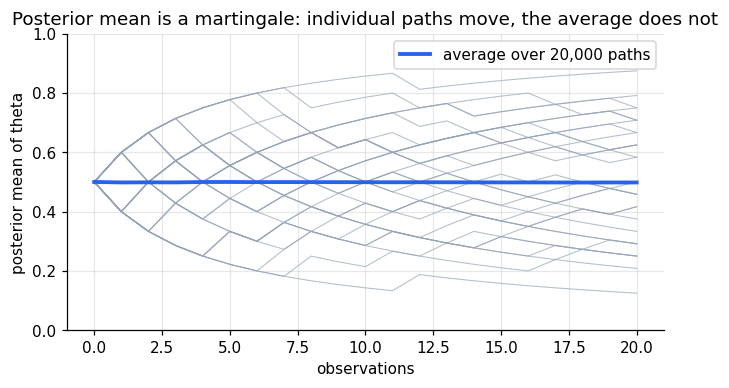

손계산 3-1: 첫 관측 뒤 0.6 또는 0.4, 예측확률 0.5 → 기댓값 0.5


In [4]:
rng=np.random.default_rng(3); n,Mpaths=20,20000
theta=rng.beta(2,2,Mpaths)                      # 사전분포에서 참값을 뽑는다
flips=rng.random((Mpaths,n))<theta[:,None]
a=2+np.cumsum(flips,1); b=2+np.cumsum(~flips,1); pm=np.hstack([np.full((Mpaths,1),.5),a/(a+b)])
plt.figure(figsize=(7,3.5))
for i in range(30): plt.plot(pm[i],color=GRAY,lw=.7,alpha=.7)
plt.plot(pm.mean(0),color=BLUE,lw=2.5,label='average over 20,000 paths')
plt.xlabel('observations'); plt.ylabel('posterior mean of theta'); plt.ylim(0,1)
plt.title('Posterior mean is a martingale: individual paths move, the average does not'); plt.legend(); savefig('fb3_martingale'); plt.show()
print('손계산 3-1: 첫 관측 뒤 0.6 또는 0.4, 예측확률 0.5 → 기댓값', .5*.6+.5*.4)

## B4. 변동성 σ를 모를 때의 옵션 가격
실제 σ=30%에서 월간 수익률 36개를 뽑아 σ²의 사후분포(역감마)를 구한다. 사후표본마다 BSM 가격을 계산해 **가격의 분포**를 보고, 평균(혼합 가격)과 점추정 가격을 행사가격별로 비교한다.

사후평균 σ ≈ 0.315,  90% 구간 [0.262, 0.376]


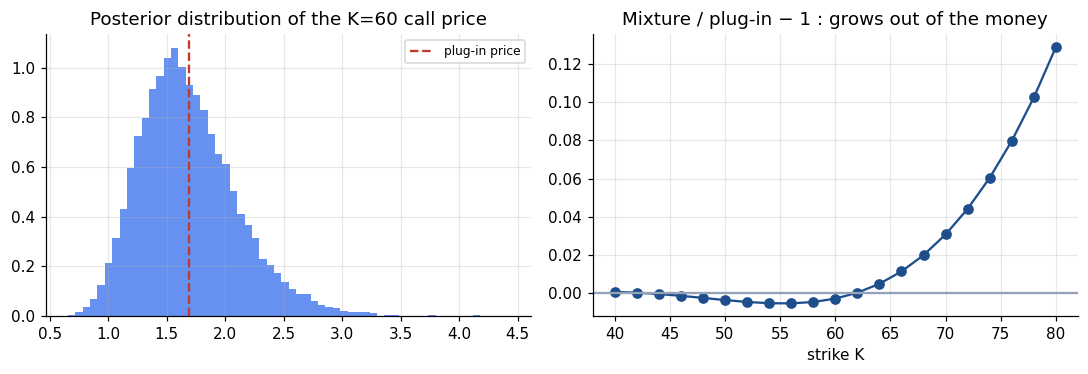

50 혼합 5.0003  점추정 5.0192
60 혼합 1.6882  점추정 1.6932
70 혼합 0.4893  점추정 0.4747


In [5]:
rng=np.random.default_rng(4); n=36; dt=1/12
ret=rng.normal(0,.30*np.sqrt(dt),n)
a0,b0=3,0.08                                      # 사전: 연율 분산 평균 0.04 (σ≈20%)
S2=(ret**2).sum()/dt                              # 연율화 제곱합
a1,b1=a0+n/2,b0+S2/2
sig_post=np.sqrt(invgamma.rvs(a1,scale=b1,size=20000,random_state=5))
sig_hat=np.sqrt(b1/(a1-1))
print(f'사후평균 σ ≈ {sig_hat:.3f},  90% 구간 [{np.quantile(sig_post,.05):.3f}, {np.quantile(sig_post,.95):.3f}]')
Ks=np.arange(40,81,2); mix=[bs(50,k,.05,sig_post,.5).mean() for k in Ks]; plug=[bs(50,k,.05,sig_hat,.5) for k in Ks]
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].hist(bs(50,60,.05,sig_post,.5),bins=60,color=BLUE,alpha=.7,density=True)
ax[0].axvline(bs(50,60,.05,sig_hat,.5),color=RED,ls='--',label='plug-in price'); ax[0].set_title('Posterior distribution of the K=60 call price'); ax[0].legend(fontsize=8)
ax[1].plot(Ks,np.array(mix)/np.array(plug)-1,'o-',color=NAVY); ax[1].axhline(0,color=GRAY)
ax[1].set_xlabel('strike K'); ax[1].set_title('Mixture / plug-in − 1 : grows out of the money')
plt.tight_layout(); savefig('fb4_sigma_uncertainty'); plt.show()
for k in (50,60,70): print(k, '혼합 %.4f  점추정 %.4f'%(bs(50,k,.05,sig_post,.5).mean(), bs(50,k,.05,sig_hat,.5)))

## B5. 베이지안 LSM
**5-1.** Hull 8경로 예제 t=2 회귀에서 계속보유가치의 사후 불확실성(자유도 2의 t분포)을 구하고 '행사가 더 낫다'는 확률을 계산한다.

**5-2.** 경로가 적고(학습 500개) 기저가 많을 때(S/K의 6차 다항식) OLS 회귀는 흔들린다. 정규 사전분포(= 릿지, 수축)를 두면 행사 규칙이 안정된다. 시드 40개로 비교한다.

In [6]:
X=np.array([1.08,1.07,0.97,0.77,0.84]); Y=np.array([0,.07,.18,.20,.09])*np.exp(-.06)
A=np.column_stack([np.ones(5),X,X**2]); b=np.linalg.lstsq(A,Y,rcond=None)[0]
res=Y-A@b; s2=res@res/2; cov=s2*np.linalg.inv(A.T@A)
for i,(x,pth) in enumerate(zip(X,[1,3,4,6,7])):
    a=np.array([1,x,x*x]); m=a@b; sd=np.sqrt(a@cov@a); ex=1.10-x
    print(f'경로{pth}: 계속가치 {m:.4f} ± {sd:.4f}, 행사 {ex:.2f}, P(행사가 낫다) = {tdist.cdf((ex-m)/sd,2):.2f}')

경로1: 계속가치 0.0367 ± 0.0547, 행사 0.02, P(행사가 낫다) = 0.39
경로3: 계속가치 0.0459 ± 0.0489, 행사 0.03, P(행사가 낫다) = 0.39
경로4: 계속가치 0.1175 ± 0.0606, 행사 0.13, P(행사가 낫다) = 0.57
경로6: 계속가치 0.1520 ± 0.0688, 행사 0.33, P(행사가 낫다) = 0.94
경로7: 계속가치 0.1564 ± 0.0508, 행사 0.26, P(행사가 낫다) = 0.91


OLS          평균 4.4051  표준편차 0.0453  최저 4.2264
Bayes ridge  평균 4.4129  표준편차 0.0163  최저 4.3735


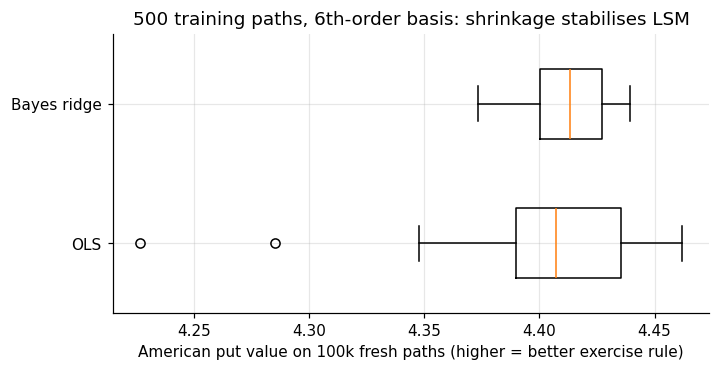

In [7]:
def paths(S0,r,s,T,n,M,rng):
    dt=T/n; Z=rng.standard_normal((M,n))
    return np.hstack([np.full((M,1),S0),S0*np.exp(np.cumsum((r-s*s/2)*dt+s*np.sqrt(dt)*Z,1))])
def basis(x,deg): return np.column_stack([x**k for k in range(deg+1)])
def fit(S,K,r,dt,deg,alpha):
    n=S.shape[1]-1; cf=np.maximum(K-S[:,n],0); tau=np.full(len(S),n); B={}
    for j in range(n-1,0,-1):
        itm=np.where(K-S[:,j]>0)[0]; x=S[itm,j]/K-1; y=cf[itm]*np.exp(-r*dt*(tau[itm]-j)); A=basis(x,deg)
        P=alpha*np.eye(deg+1); P[0,0]=0                      # 절편은 수축하지 않는다
        b=np.linalg.solve(A.T@A+P,A.T@y); B[j]=b
        stop=itm[(K-S[itm,j])>A@b]; cf[stop]=K-S[stop,j]; tau[stop]=j
    return B
def price(S,K,r,dt,B,deg):
    n=S.shape[1]-1; alive=np.ones(len(S),bool); pv=np.zeros(len(S))
    for j in range(1,n):
        idx=np.where(alive&(K-S[:,j]>0))[0]; ex=K-S[idx,j]
        stop=idx[ex>basis(S[idx,j]/K-1,deg)@B[j]]; pv[stop]=(K-S[stop,j])*np.exp(-r*dt*j); alive[stop]=False
    pv[alive]=np.maximum(K-S[alive,n],0)*np.exp(-r*dt*n); return pv.mean()
S0,K,r,s,T,n=36,40,.06,.2,1,25; dt=T/n
ev=paths(S0,r,s,T,n,100_000,np.random.default_rng(99))
res={}
for name,alpha in [('OLS',1e-10),('Bayes ridge',1.0)]:
    res[name]=[price(ev,K,r,dt,fit(paths(S0,r,s,T,n,500,np.random.default_rng(sd)),K,r,dt,6,alpha),6) for sd in range(40)]
for k,v in res.items(): print(f'{k:12s} 평균 {np.mean(v):.4f}  표준편차 {np.std(v):.4f}  최저 {np.min(v):.4f}')
plt.figure(figsize=(7,3.3))
plt.boxplot(list(res.values()),tick_labels=list(res.keys()),vert=False,widths=.5)
plt.xlabel('American put value on 100k fresh paths (higher = better exercise rule)')
plt.title('500 training paths, 6th-order basis: shrinkage stabilises LSM'); savefig('fb5_bayes_lsm'); plt.show()

## B6. 응용 — 신약 개발 실물옵션
지금 20을 들여 2상 임상을 하면, 성공 시 1년 뒤 60을 투자해 가치 100의 사업을 얻는다. 성공확률 θ의 사전분포 Beta(2,3), 예비 코호트 4개 중 성공 수 k로 갱신한다. 기술적 위험은 시장과 무관하므로 시장위험가격 0 → **사후확률을 그대로 위험중립 확률로 쓴다** (Hull 28장).

성공 0/4 → 사후 성공확률 0.222 → 진행 가치 -11.54  (중단)
성공 1/4 → 사후 성공확률 0.333 → 진행 가치 -7.32  (중단)
성공 2/4 → 사후 성공확률 0.444 → 진행 가치 -3.09  (중단)
성공 3/4 → 사후 성공확률 0.556 → 진행 가치 +1.14  (진행)
성공 4/4 → 사후 성공확률 0.667 → 진행 가치 +5.37  (진행)
사전만 쓰면: q=0.4 → -4.78


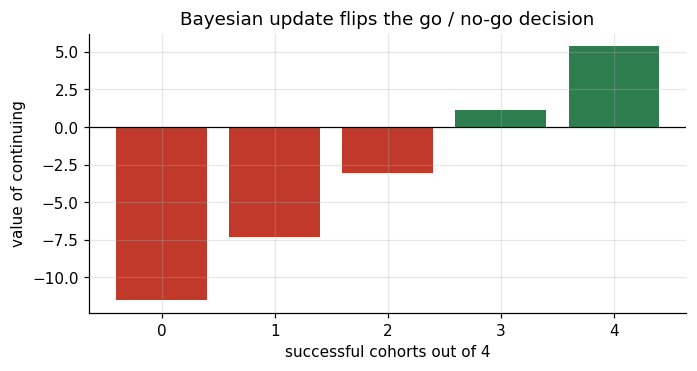

In [8]:
ks=np.arange(0,5); q=(2+ks)/(2+3+4); val=-20+np.exp(-.05)*q*40
for k,qq,v in zip(ks,q,val): print(f'성공 {k}/4 → 사후 성공확률 {qq:.3f} → 진행 가치 {v:+.2f}  ({"진행" if v>0 else "중단"})')
print('사전만 쓰면: q=0.4 → %.2f'%(-20+np.exp(-.05)*.4*40))
plt.figure(figsize=(7,3.3)); plt.bar(ks,val,color=[GREEN if v>0 else RED for v in val]); plt.axhline(0,color='k',lw=.8)
plt.xlabel('successful cohorts out of 4'); plt.ylabel('value of continuing'); plt.title('Bayesian update flips the go / no-go decision'); savefig('fb6_rnd_option'); plt.show()